
# Lecture 22 — Single-Cycle vs Multi-Cycle Processors

**Professor:** Dr. Janibul Bashir  
**Lecture:** [Single-Cycle & Multi-Cycle Processors](https://youtu.be/EayIuLNBukQ?utm_source=chatgpt.com)  
**Transcript:** Retrieved using vidIQ

This lecture is heavily focused on performance, and the professor repeats the same underlying principle across multiple examples.

We'll compress that repetition while preserving the derivations and numerical problems.

---

## Part 1. What Is a Single-Cycle Processor?

> **Definition:** A single-cycle processor completes the execution of one machine instruction in exactly **one clock cycle**.

Recall our five stages:

1. **IF** — Instruction Fetch
2. **ID** — Instruction Decode
3. **EX** — Execute
4. **MEM** — Memory Access
5. **WB** — Writeback

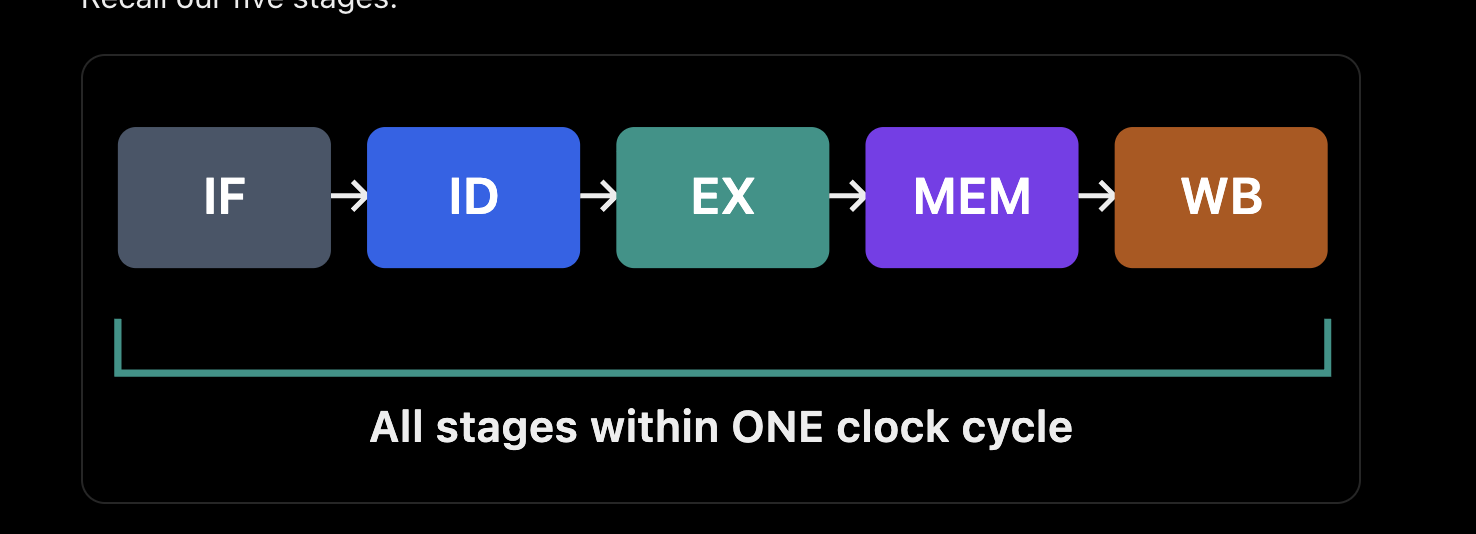

### Crucial Point

> 📌 **One cycle doesn't mean each stage takes one cycle.** It means all necessary processing must finish before that single cycle ends.

---

## 2. How Long Should the Clock Cycle Be?

Let's define the variables first.

| Variable | Meaning |
|---|---|
| $T_{\text{clk}}$ | Duration of one clock cycle |
| $d_1,d_2,\ldots,d_5$ | Delays of the five stages |
| $f$ | Clock frequency |

For an instruction passing through all five stages:

$$
\boxed{
T_{\text{clk}} \geq d_1+d_2+d_3+d_4+d_5
}
$$

This simplified formula assumes the stages form the longest relevant path and ignores additional register-timing overhead.

But the processor executes many types of instructions, each potentially with different delays.

Therefore, the clock period must accommodate the **slowest instruction**.

$$
\boxed{
T_{\text{clk}} \geq \max(T_{\text{instruction}})
}
$$

### Example From the Professor

Suppose:

| Instruction | Execution Delay |
|---|---|
| ADD | 3 ns |
| MUL | 4 ns |
| SHIFT | 5 ns |
| LOAD | 6 ns |

**Which clock period should we select?**

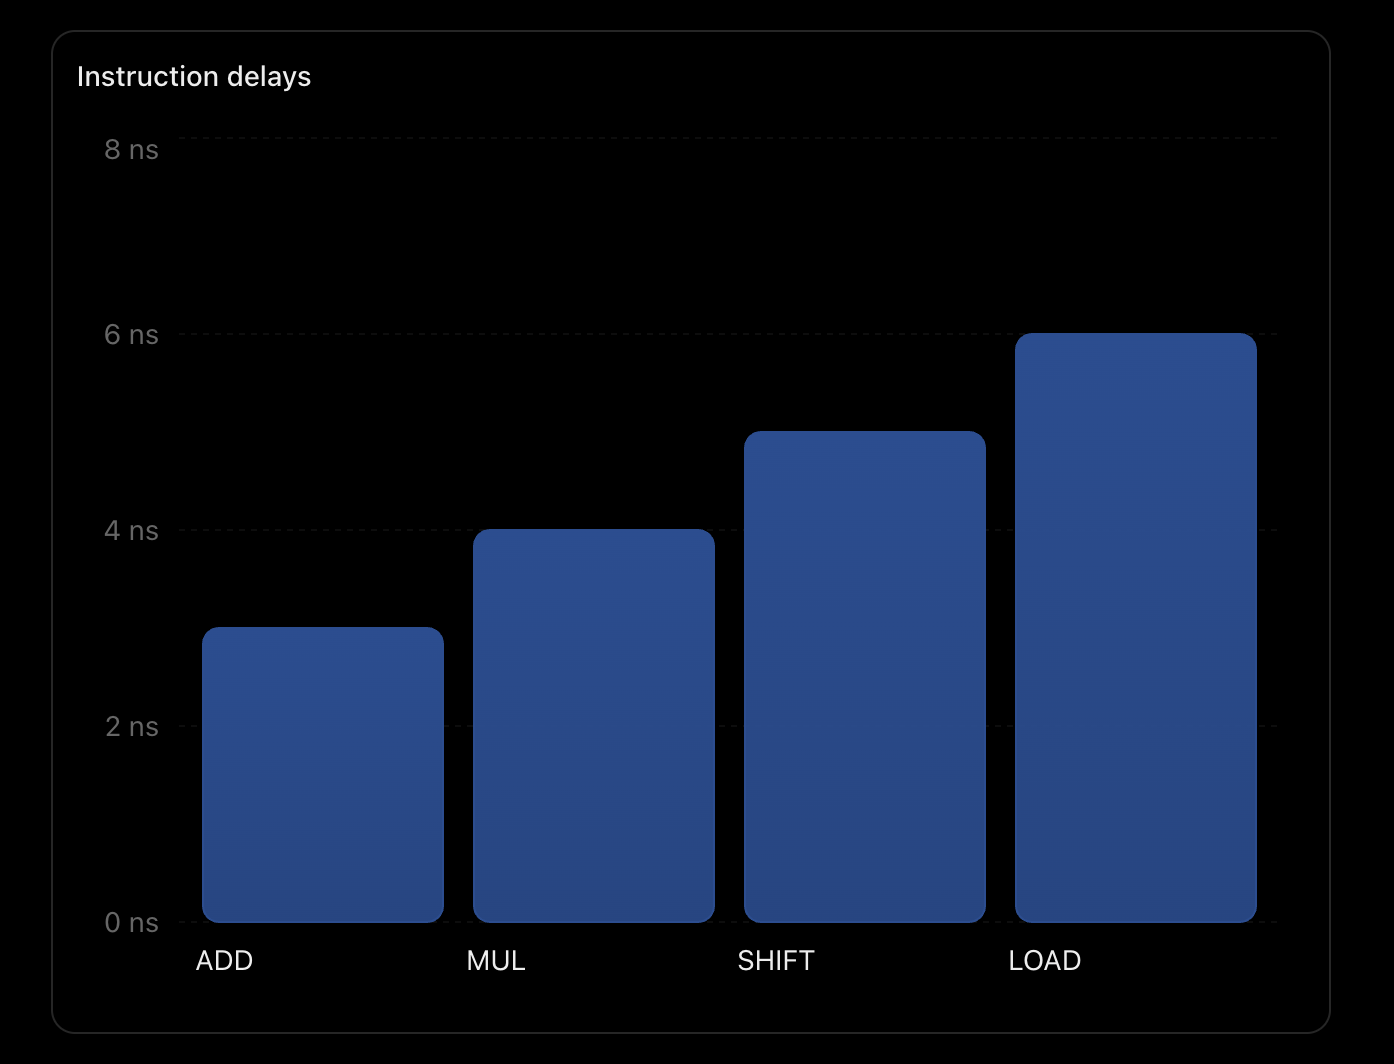

If we choose **3 ns**, ADD completes, but LOAD needs **6 ns** and cannot finish in time.

So the minimum clock period is:

$$
\boxed{T_{\text{clk}}=6\text{ ns}}
$$

Even ADD, which requires only 3 ns of processing, occupies the entire **6 ns cycle** before the next instruction can begin.

> 💡 This unused time is the major inefficiency of the single-cycle design.

---

## 3. Clock Frequency

We know:

$$
\boxed{
f=\frac{1}{T_{\text{clk}}}
}
$$

For:

$$
T_{\text{clk}}=6\text{ ns}
$$

Substitute:

$$
f=\frac{1}{6\times10^{-9}}
$$

Therefore:

$$
\boxed{
f\approx0.167\text{ GHz}=166.7\text{ MHz}
}
$$

### Relationship Between Frequency and Clock Period

If we increase the frequency, the cycle period decreases.

But reducing the cycle period below the required circuit delay would violate timing constraints.

> 📌 **Therefore, the slowest instruction limits the maximum clock frequency in a single-cycle processor.**

---

## 4. Multi-Cycle Processor — The Improvement

Instead of executing the entire instruction in one clock cycle, why not divide instruction processing into several cycles?

That's the idea behind a **multi-cycle processor**.

> **Definition:** A multi-cycle processor divides instruction execution into multiple clock cycles, allowing different instructions to require different numbers of cycles.

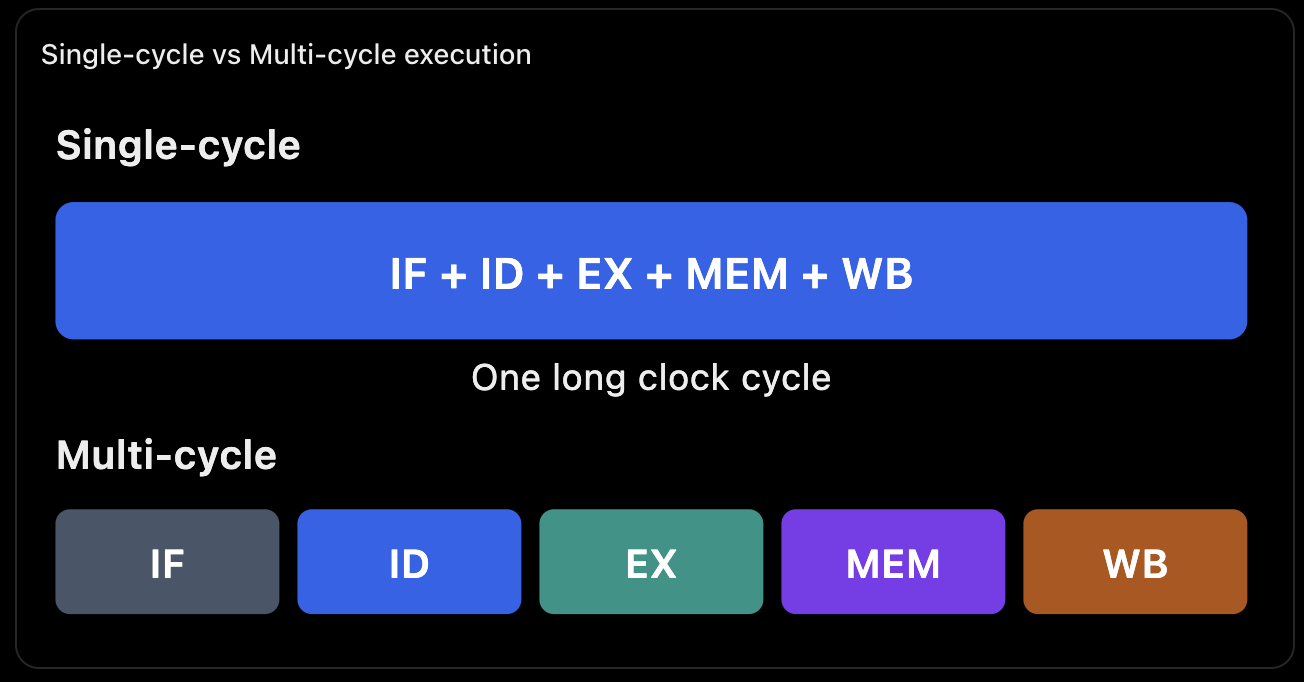

Each stage can occupy its own clock cycle, with intermediate results stored in temporary registers.

Now the clock period is determined by the **slowest stage**, rather than the slowest complete instruction.

$$
\boxed{
T_{\text{clk}}\geq\max(d_1,d_2,\ldots,d_5)
}
$$

### Numerical Example

Suppose the stage delays are:

| Stage | Delay |
|---|---|
| IF | 1 ns |
| ID | 1 ns |
| EX | 2 ns |
| MEM | 3 ns |
| WB | 1 ns |

The slowest stage is **MEM**, requiring 3 ns.

Therefore:

$$
T_{\text{clk}}=\boxed{3\text{ ns}}
$$

### Calculating Clock Frequency

Using:

$$
f=\frac{1}{T_{\text{clk}}}
$$

Substitute:

$$
f=\frac{1}{3\times10^{-9}}
$$

Therefore:

$$
\boxed{
f\approx0.333\text{ GHz}=333.3\text{ MHz}
}
$$

### Key Difference

| Feature | Single-Cycle | Multi-Cycle |
|---|---|---|
| Clock-period constraint | Longest complete instruction path | Longest individual cycle's work |
| Cycles per instruction | Exactly 1 | Multiple |
| Intermediate results | Completed within one cycle | Stored between cycles |
| Clock frequency | Limited by longest instruction | Limited by longest stage |
| Instruction execution | One cycle | Several cycles |

> 💡 **Key difference:** Single-cycle timing depends on the longest instruction path; multi-cycle timing depends on the longest individual cycle's work.

The multi-cycle processor may have a higher clock frequency, but it requires multiple cycles per instruction.

> 📌 **Important:** We cannot decide which processor is faster just by counting cycles. We must consider both clock-cycle duration and cycles per instruction.

---


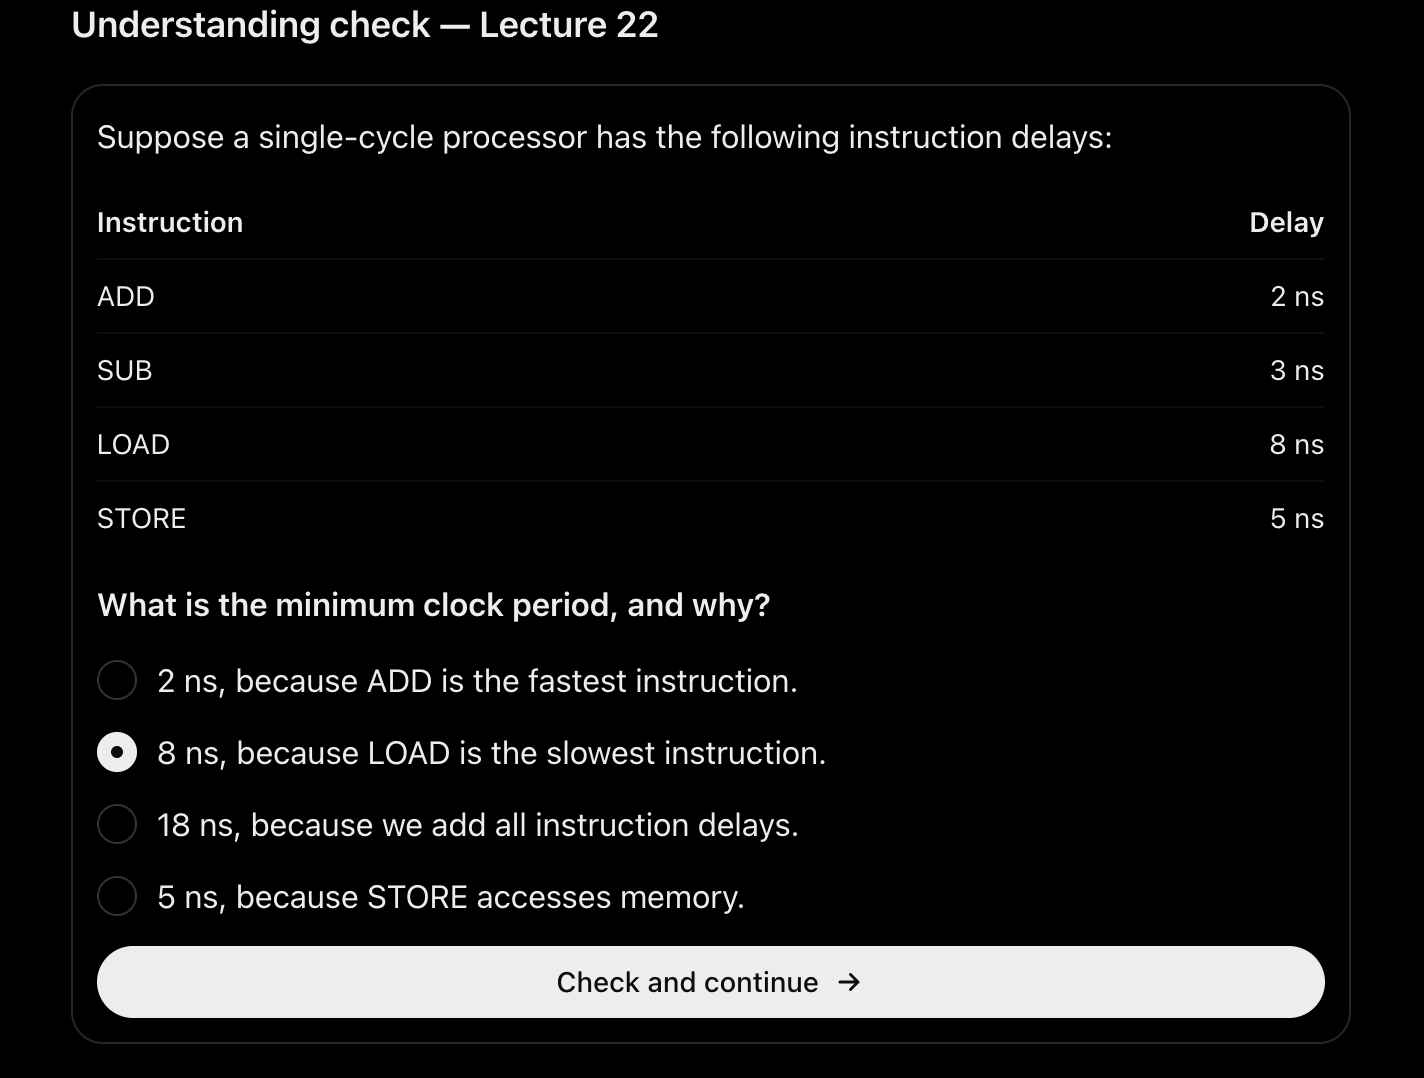

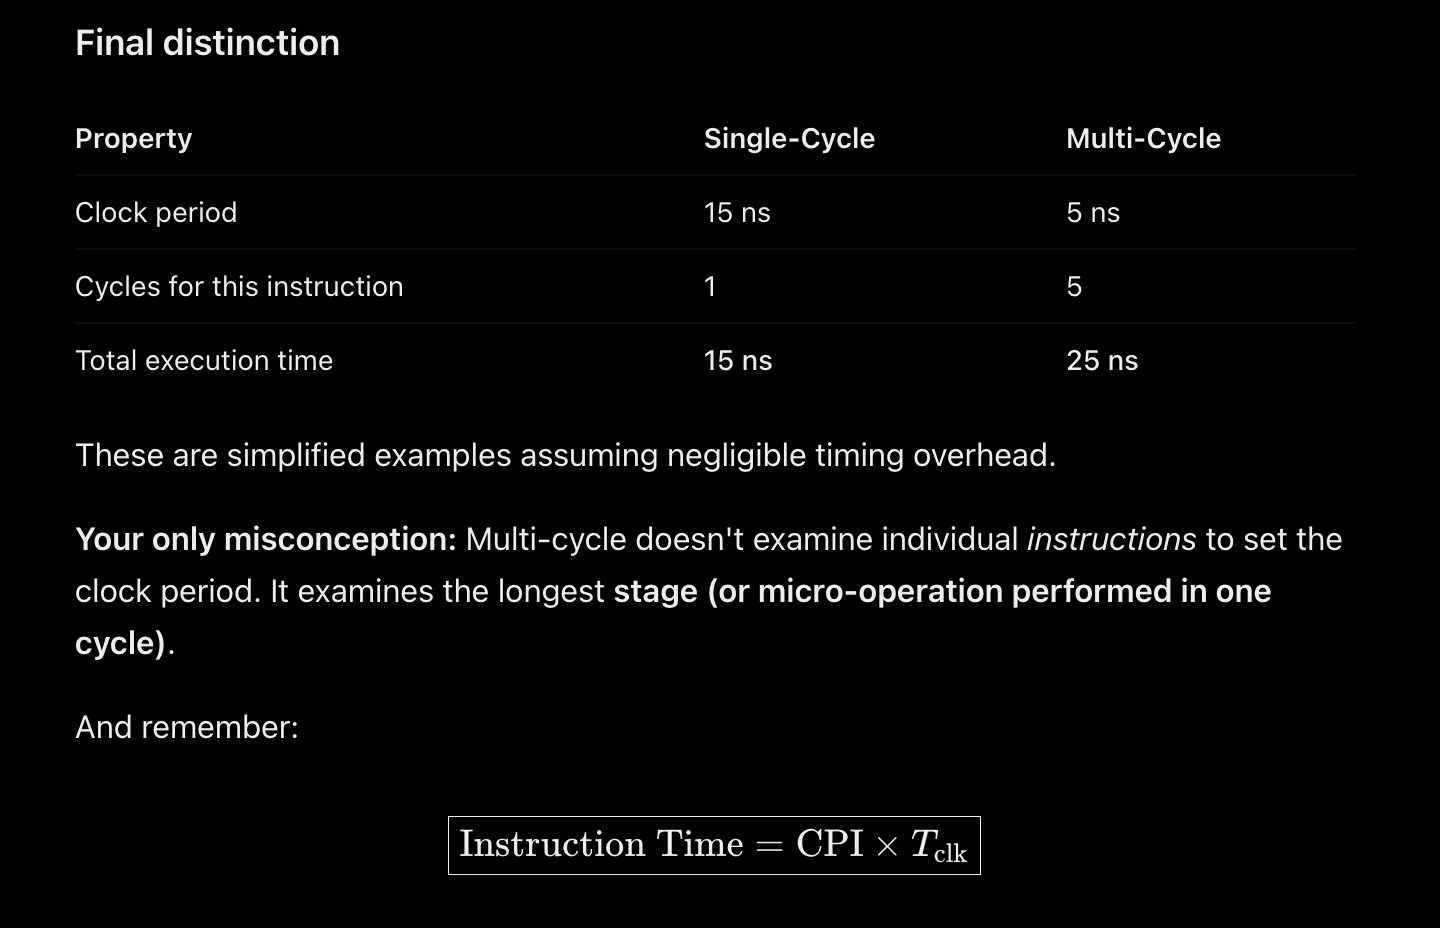

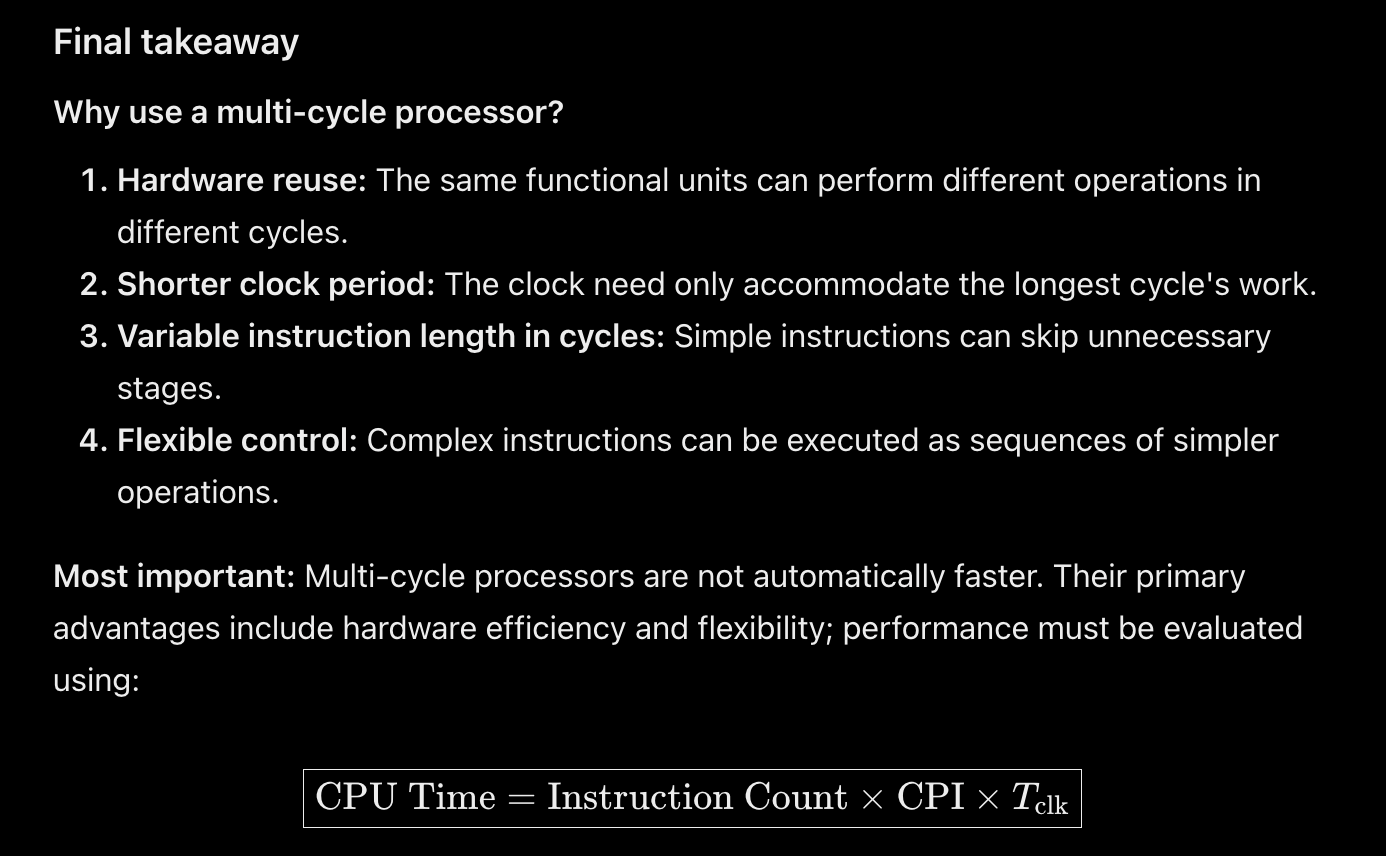


# Lecture 22 — Part 2: CPI, IPC and Processor Performance

**Professor's Transcript:** Approximately 29:00–54:40

---

## 1. What Is CPI?

**CPI (Cycles Per Instruction)** represents the average number of clock cycles required to execute one instruction.

The formula is:

$$
\boxed{CPI=\frac{\text{Total Clock Cycles}}{\text{Instruction Count}}}
$$

Where:

- **Total Clock Cycles** = Clock cycles consumed executing the program.
- **Instruction Count (IC)** = Number of executed instructions.

### Example

Suppose a processor executes **100 instructions in 400 clock cycles**.

$$
CPI=\frac{400}{100}=\boxed{4}
$$

That means the processor takes an average of **4 cycles per instruction**.

### Single-Cycle vs Multi-Cycle

In the simplified processors we're studying:

| Processor | CPI |
|---|---|
| Single-cycle | 1 |
| Non-pipelined multi-cycle | Greater than 1 |

**But here's an important question:**

Does a smaller CPI always mean a faster processor?

**No.** We must also consider the duration of each clock cycle.

---

## 2. What Is IPC?

**IPC (Instructions Per Cycle)** is the average number of instructions completed per clock cycle.

$$
\boxed{IPC=\frac{\text{Instruction Count}}{\text{Total Clock Cycles}}}
$$

For the same program:

$$
IPC=\frac{100}{400}=\boxed{0.25}
$$

Therefore:

$$
\boxed{IPC=\frac{1}{CPI}}
$$

And:

$$
\boxed{CPI=\frac{1}{IPC}}
$$

These reciprocal relationships apply when both metrics are measured for the same instruction stream and execution interval.

### Interactive Example — Explore CPI and IPC

Suppose a processor executes exactly **100 instructions**.

Change the number of clock cycles it takes.

![Explore CPI and IPC — Interactive Example](image(2).png)

The screenshot shows:

| Quantity | Value |
|---|---|
| Instruction Count | 100 |
| Total Clock Cycles | 400 |
| CPI | **4.00 cycles/instruction** |
| IPC | **0.25 instructions/cycle** |

> 💡 **Notice:** When total cycles decrease while instruction count remains fixed, CPI decreases and IPC increases.

---

## 3. Deriving the CPU Execution-Time Formula

Don't memorize this formula without understanding where it comes from.

### Step 1: Start With CPI

$$
CPI=\frac{\text{Total Clock Cycles}}{IC}
$$

### Step 2: Rearrange

$$
\text{Total Clock Cycles}=IC\times CPI
$$

### Step 3: Introduce Clock Period

Now suppose one clock cycle takes $T_{\text{clk}}$ seconds.

Total execution time is:

$$
\text{Total Cycles}\times\text{Time per Cycle}
$$

### Step 4: Substitute

$$
\boxed{\text{CPU Time}=IC\times CPI\times T_{\text{clk}}}
$$

Since:

$$
T_{\text{clk}}=\frac{1}{f}
$$

We also get:

$$
\boxed{\text{CPU Time}=\frac{IC\times CPI}{f}}
$$

### Variables

| Variable | Meaning |
|---|---|
| $IC$ | Instruction count |
| $CPI$ | Average clock cycles per instruction |
| $T_{\text{clk}}$ | Clock period |
| $f$ | Clock frequency |

> 📌 **Very Important:** This is the main processor-performance formula for your exam.

---

## 4. Professor's Numerical Example — Which Processor Is Faster?

**Transcript:** Approximately 34:20–36:14

The professor compares two processors.

### Processor A — Single-Cycle

| Parameter | Value |
|---|---|
| Processor | Single-cycle A |
| CPI | 1 |
| Clock Period | 10 ns |

### Processor B — Multi-Cycle

| Parameter | Value |
|---|---|
| Processor | Multi-cycle B |
| CPI | 4 |
| Clock Period | 2 ns |

At first glance, Processor A looks faster because its CPI is only 1.

**But let's calculate.**

### Step 1: Processor A

$$
T_A=CPI_A\times T_{\text{clk},A}
$$

Substitute:

$$
T_A=1\times10
$$

$$
\boxed{T_A=10\text{ ns/instruction}}
$$

### Step 2: Processor B

$$
T_B=CPI_B\times T_{\text{clk},B}
$$

Substitute:

$$
T_B=4\times2
$$

$$
\boxed{T_B=8\text{ ns/instruction}}
$$

### Step 3: Compare Execution Times

![Average Time Per Instruction — Single-Cycle vs Multi-Cycle](image(3).png)

| Processor | CPI | Clock Period | Average Time per Instruction |
|---|---|---|---|
| Single-cycle A | 1 | 10 ns | 10 ns |
| Multi-cycle B | 4 | 2 ns | **8 ns** |

Lower execution time means better performance, assuming both run the same instruction count.

### Result

**✅ Processor B is faster even though its CPI is larger.**

**Why?**

Because its clock cycle is much shorter.

This is exactly what the professor wants you to understand:

$$
\boxed{\text{CPI alone cannot determine processor performance.}}
$$

---

## 5. Speedup — How Much Faster Is B?

This is an important numerical formula.

$$
\boxed{\text{Speedup}=\frac{\text{Old Execution Time}}{\text{New Execution Time}}}
$$

Here:

- Old Execution Time = 10 ns/instruction.
- New Execution Time = 8 ns/instruction.

Substitute:

$$
\text{Speedup}=\frac{10}{8}=\boxed{1.25}
$$

Thus, Processor B achieves **1.25× the performance** of Processor A, or a **25% performance improvement**.

### Important Percentage Distinction

| Metric | Calculation | Result |
|---|---|---|
| Execution time reduction | $(10-8)/10\times100$ | **20%** |
| Performance improvement | $(1.25-1)\times100$ | **25%** |

> 📌 **Be careful:** Execution time is reduced by 20%, while performance increases by 25%. Those are different percentages.

---

## 6. Deriving the Performance Equation

Your professor derives an expression connecting performance, IPC and clock frequency.

### Step 1: CPU Execution Time

For a fixed instruction count:

$$
\text{CPU Time}=\frac{IC\times CPI}{f}
$$

### Step 2: Define Performance

Performance is inversely proportional to execution time:

$$
P\propto\frac{1}{\text{CPU Time}}
$$

### Step 3: Substitute

$$
P\propto\frac{f}{IC\times CPI}
$$

### Step 4: Keep Instruction Count Constant

When comparing processors executing the same instruction count, $IC$ is constant:

$$
P\propto\frac{f}{CPI}
$$

### Step 5: Use the CPI–IPC Relationship

But:

$$
IPC=\frac{1}{CPI}
$$

Therefore:

$$
\boxed{P\propto IPC\times f}
$$

This is the professor's performance relationship.

> 📝 **Important clarification:** More precisely, $IPC\times f$ gives instruction throughput (instructions per second). It is a valid performance comparison when processors execute the same workload with comparable instruction counts.

### What Improves Performance?

We can improve instruction throughput by:

- **Increasing IPC:** Executing more instructions per cycle.
- **Increasing clock frequency:** More cycles per second.

But neither can be increased indefinitely because of hardware, power and timing constraints.

---

## 7. All Formulas for Lecture 22 So Far

| Quantity | Formula |
|---|---|
| CPI | $\dfrac{\text{Total Cycles}}{IC}$ |
| IPC | $\dfrac{IC}{\text{Total Cycles}}$ |
| CPI–IPC relationship | $IPC=\dfrac{1}{CPI}$ |
| Clock period | $T_{\text{clk}}=\dfrac{1}{f}$ |
| CPU execution time | $IC\times CPI\times T_{\text{clk}}$ |
| CPU execution time using frequency | $\dfrac{IC\times CPI}{f}$ |
| Speedup | $\dfrac{T_{\text{old}}}{T_{\text{new}}}$ |
| Instruction throughput | $IPC\times f$ |

---



# Lecture 22 — Part 3: Improving Processor Performance

We've established the main performance relationship:

$$
\boxed{\text{Instruction Throughput}=IPC\times f}
$$

Where:

- $IPC$ = Average instructions completed per clock cycle.
- $f$ = Clock frequency in cycles per second.

This gives us two primary ways to improve throughput:

1. Increase the number of instructions completed per cycle.
2. Increase the number of clock cycles per second.

But each approach has practical limits.

---

## 1. Can We Improve a Single-Cycle Processor?

**Professor's Transcript:** 54:40–1:03:47

Consider a single-cycle processor with only one execution path:

```text
IF → ID → EX → MEM → WB
```

It completes one instruction per clock cycle.

Therefore:

$$
CPI=1,\qquad IPC=1
$$

### Can We Improve Its IPC Without Changing the Architecture?

Not in this basic single-issue design.

It already completes one instruction in every cycle.

### Can We Increase the Frequency?

Only if we reduce the critical-path delay.

Simply increasing the clock frequency beyond the hardware's timing limit would make the processor unreliable.

This motivates two architectural improvements:

- **Superscalar execution:** Process multiple instructions in parallel.
- **Pipelining:** Overlap the execution stages of different instructions.

The professor discusses superscalar execution first.

---

## 2. What Is a Superscalar Processor?

**Professor's Transcript:** 55:58–1:00:46

Think of the difference between **one checkout counter and four checkout counters** in a supermarket.

With one counter, one customer is served at a time.

With four counters, up to four customers can be served simultaneously.

A **superscalar processor** uses a similar idea: it has sufficient hardware resources to issue multiple instructions during the same clock cycle.

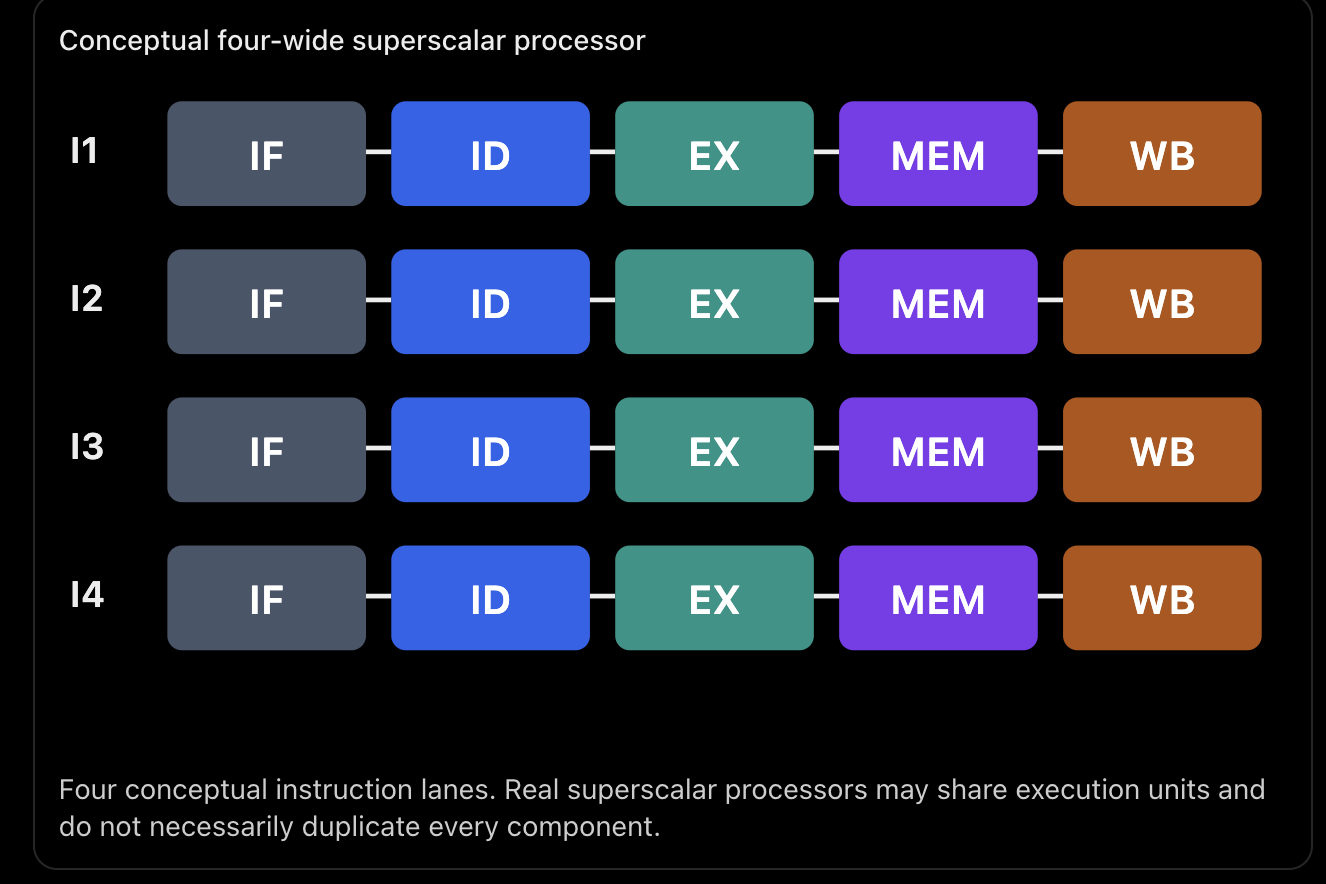
*Four conceptual instruction lanes. Real superscalar processors may share execution units and do not necessarily duplicate every component.*

### 2.1 What Is Issue Width?

**Issue width** is the maximum number of instructions a processor can issue to execution resources per clock cycle.

| Issue Width | Maximum Instructions Issued per Cycle |
|---|---|
| 1 | 1 |
| 2 | 2 |
| 4 | 4 |
| 8 | 8 |

> 📌 An issue width of 4 doesn't guarantee that four instructions complete every cycle. Dependencies, resource limitations and pipeline stalls can reduce actual IPC.

### 2.2 Professor's Numerical Example

Suppose a processor sustains completion of **four instructions every clock cycle**.

Then:

$$
IPC=\frac{4}{1}=\boxed{4}
$$

And:

$$
CPI=\frac{1}{4}=\boxed{0.25}
$$

> 💡 **Important:** CPI below 1 is possible when multiple instructions complete per cycle.

The professor refers to such a machine as a **multiple-issue processor**.

---

## 3. Can Pipelining Improve IPC Without Superscalar Execution?

**Professor's Transcript:** 1:05:00–1:11:00

**Yes!** This is the key idea connecting Lecture 22 to Lecture 23.

Suppose a non-pipelined multi-cycle processor needs five cycles to execute one instruction:

```text
Cycle 1: IF
Cycle 2: ID
Cycle 3: EX
Cycle 4: MEM
Cycle 5: WB
```

It executes instructions sequentially, so:

$$
CPI=5,\qquad IPC=0.2
$$

But why should the instruction-fetch hardware remain idle while another instruction is using the ALU?

We could fetch the next instruction while the previous instruction moves to Decode.

**This is pipelining.**

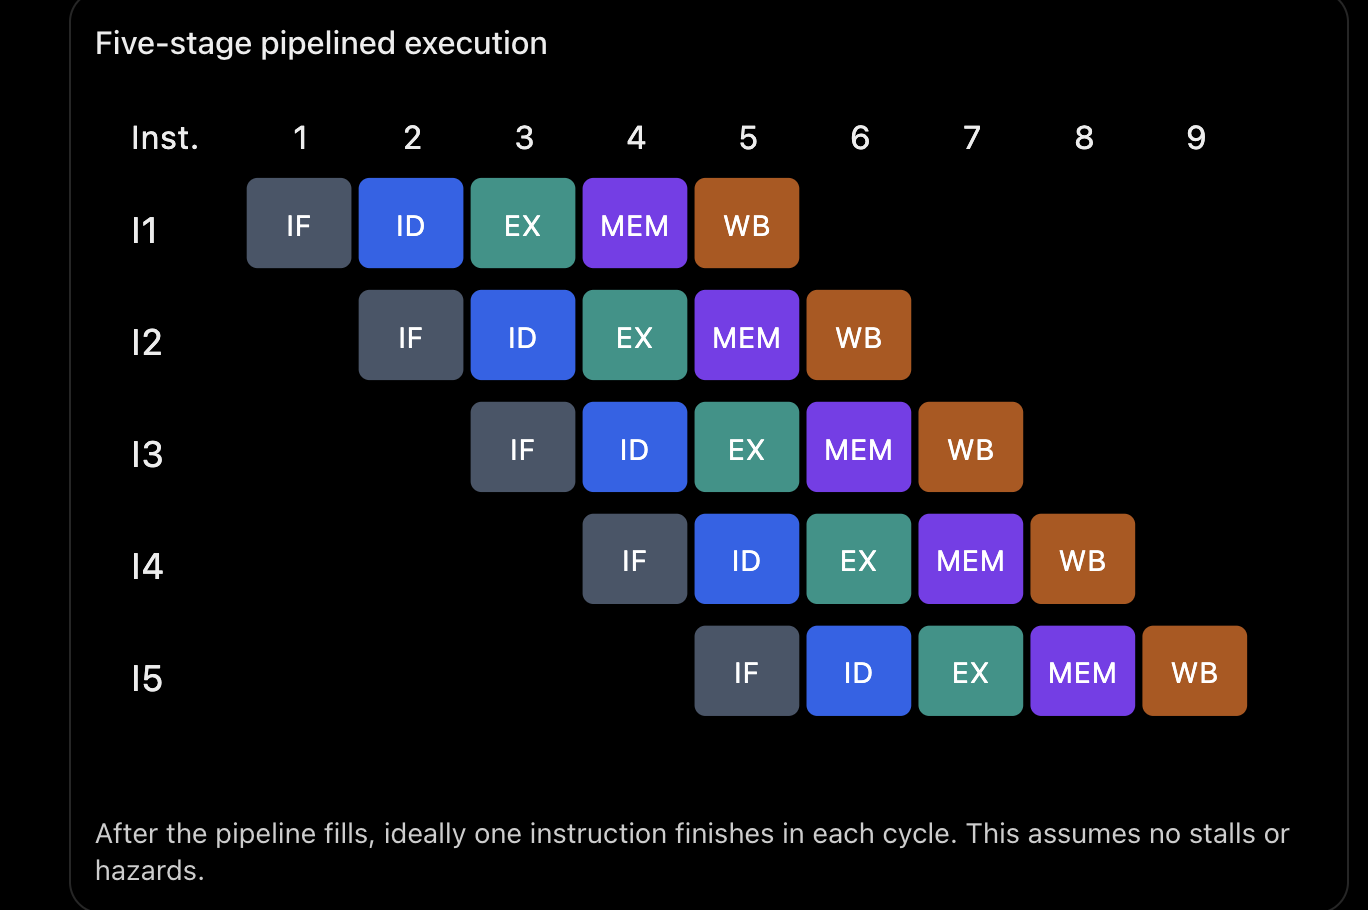
*After the pipeline fills, ideally one instruction finishes in each cycle. This assumes no stalls or hazards.*

### 3.1 What Happens During Pipelining?

Notice what happens:

- Instruction `I1` advances to Decode.
- Meanwhile, `I2` can enter Fetch.
- In the next cycle, `I1` advances to Execute, `I2` to Decode, and `I3` enters Fetch.

Once the pipeline is full, ideally one instruction completes every cycle.

Therefore, for a single-issue pipeline in steady state:

$$
\boxed{IPC\rightarrow1,\qquad CPI\rightarrow1}
$$

The professor emphasizes that a **single-issue pipeline cannot sustain IPC greater than 1**.

To achieve higher IPC, we need multiple-issue capability.

### 3.2 Important Exam Distinction

> 📌 **Pipelining improves throughput, not necessarily the latency of an individual instruction.**

An instruction may still require five pipeline stages, but several instructions are processed concurrently.

We'll study pipeline hazards and stalls in the next lectures.

---

## 4. Why Can't We Increase Clock Frequency Indefinitely?

**Professor's Transcript:** 1:14:18–1:18:23

The professor ends Lecture 22 by discussing the relationship between:

- Clock frequency
- Power consumption
- Temperature

### 4.1 Dynamic Power Equation

A simplified dynamic power equation is:

$$
\boxed{P_{\text{dynamic}}=\alpha CV^2f}
$$

Where:

| Variable | Meaning | Unit |
|---|---|---|
| $P_{\text{dynamic}}$ | Dynamic switching power consumed by the circuit | Watts (W) |
| $\alpha$ | Switching activity factor | Dimensionless |
| $C$ | Effective switched capacitance | Farads (F) |
| $V$ | Supply voltage | Volts (V) |
| $f$ | Clock frequency | Hertz (Hz) |

### 4.2 What Does This Equation Tell Us?

If we increase frequency while keeping everything else constant:

$$
P_{\text{dynamic}}\propto f
$$

Therefore, **doubling frequency approximately doubles dynamic power**, assuming voltage, capacitance and switching activity stay constant.

### 4.3 Why Does Voltage Matter?

Increasing frequency can also require a higher supply voltage.

This further increases power because of the $V^2$ term.

$$
P_{\text{dynamic}}=\alpha CV^2f
$$

Greater power consumption generates more heat.

### 4.4 Temperature and Thermal Limits

As temperature rises:

- Leakage current can increase.
- Additional leakage increases power consumption.
- Increased power consumption can produce more heat.
- Cooling and thermal-management limits constrain sustainable frequency.

The professor uses this to explain why processor designers cannot rely exclusively on higher clock frequencies.

> 📝 **Terminology clarification:** The lecture's phrase **thermal breakdown** refers broadly to overheating and its damaging consequences. In processor engineering, we commonly discuss thermal design limits, leakage, thermal throttling and reliability constraints.

---

## 5. Lecture 22 — Final Exam Revision

| Concept | Key Point |
|---|---|
| Single-cycle processor | One instruction finishes in one long clock cycle |
| Multi-cycle processor | One instruction takes multiple shorter cycles |
| Single-cycle clock period | Determined by the slowest instruction |
| Multi-cycle clock period | Determined by the slowest cycle/stage |
| CPI | Average cycles per instruction |
| IPC | Average instructions completed per cycle |
| Superscalar | Multiple instructions can be issued in a cycle |
| Issue width | Maximum number of instructions issued per cycle |
| Pipelining | Overlaps instruction execution stages |
| Dynamic power | Approximately $\alpha CV^2f$ |

### Two Most Important Formulas

**1. CPU Execution Time**

$$
\boxed{T_{\text{CPU}}=\frac{IC\times CPI}{f}}
$$

**2. Instruction Throughput**

$$
\boxed{\text{Instruction Throughput}=IPC\times f}
$$

---


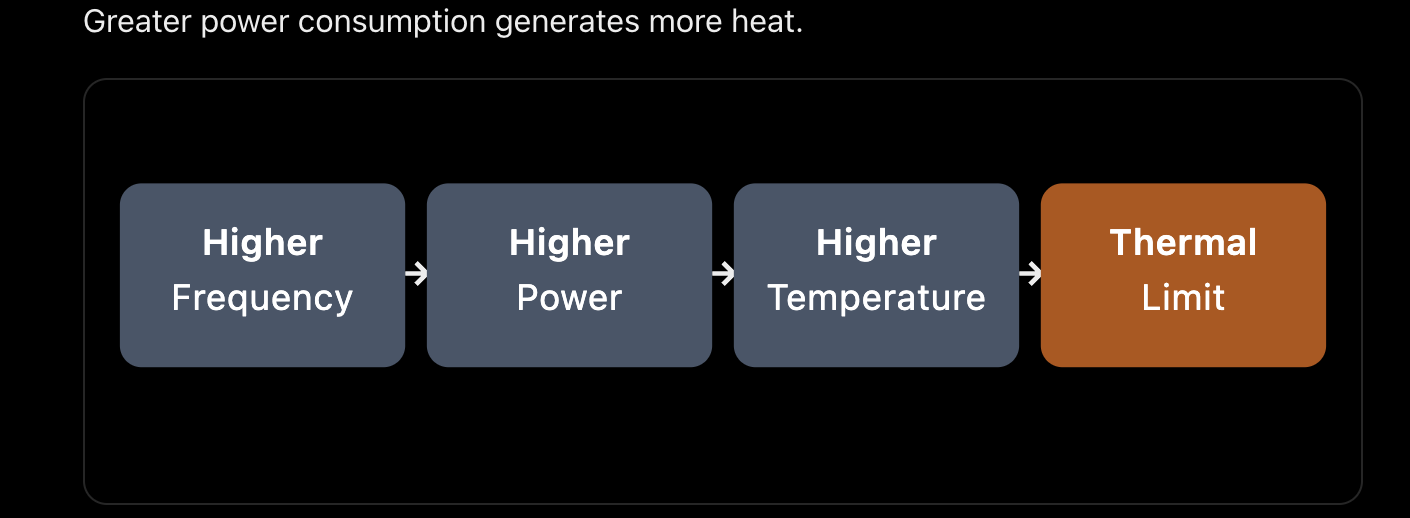